# NB 07b — KTaO$_3$ benchmarks (Ω triangulation + shift-alignment, η_KTO, LST, Barrett)

Turn 4B Amendment-2 §7. Benchmark notebook: consumes only `literature_io`
(η computed inline here; the `eta_fit` function is built later in `eta.py` and
consumed by NB 08). (1) Ω(T) triangulation Meier+Ranalli+Vogt with Vogt as the
shift-alignment tie-breaker; (2) η_KTO(T) = (γ/2)/Ω from Vogt Fig. 5 — underdamped,
≈0.127 @300 K; (3) Λ²_KTO stays a **bracket** (all sources q=0); (4) LST 1/ε vs Ω²
+ Barrett T₁ (QPE scale). **GATE:** η_KTO < 0.5 (underdamped); STOP for sign-off.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)

from fekappa.plots import set_publication_style
from fekappa import literature_io as lit
set_publication_style()

FLAGS = []
def flag(item, ok, note=""):
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else "")); FLAGS.append((item, ok, note))

def eta_curve(dfo, dfg, ocol="Omega_meV", gcol="gamma_meV", ometh=None):
    """eta(T) = (gamma/2)/Omega, gamma interpolated onto Omega's T grid. gamma=FWHM -> /2."""
    o = dfo[dfo["method"] == ometh] if ometh else dfo
    o = o.sort_values("T_K"); g = dfg.sort_values("T_K")
    gT = g["T_K"].to_numpy(float); gV = g[gcol].to_numpy(float)
    oT = o["T_K"].to_numpy(float); oV = o[ocol].to_numpy(float)
    m = (oT >= gT.min()) & (oT <= gT.max())
    oT, oV = oT[m], oV[m]
    return oT, 0.5 * np.interp(oT, gT, gV) / oV
print("PROJECT_ROOT:", PROJECT_ROOT)


PROJECT_ROOT: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph


## 1. Ω(T) triangulation + shift-alignment (Vogt tie-breaker)


@~300 K (meV): Vogt exp 10.15 (T=294) | Meier calc 10.86 | Ranalli expt 10.29 | Ranalli shifted-MLFF 9.05
  Vogt exp closer to Meier (0.71) than to Ranalli-shifted (1.10)
  -> Ranalli -4.30 meV down-shift is over-applied above ~150 K (experimental
     anchors Vogt+Ranalli-expt and Meier-calc cluster ~10.1-10.9; shifted-MLFF 9.05 low).
  TWO experiments agree: Ranalli-expt 10.29 vs Vogt 10.15 (Delta=0.14 meV)
  -> the tie-breaker is two INDEPENDENT experiments vs the over-shifted MLFF curve,
     not Vogt alone.


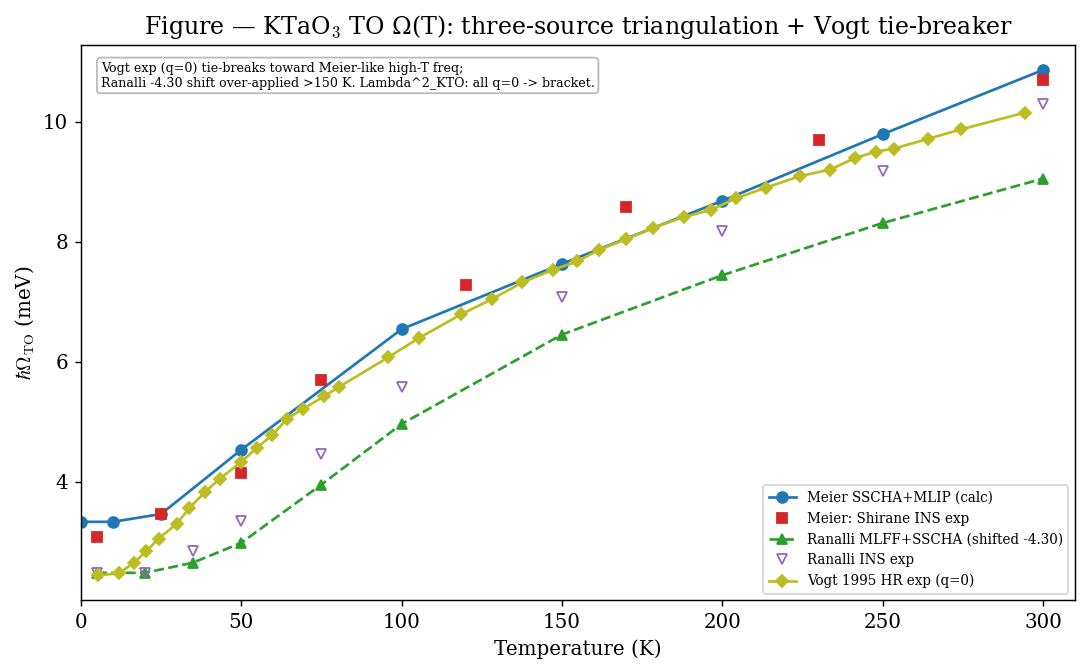

saved fig_KTaO3_omega_T_triangulation.{png,pdf}


In [2]:
mei = lit.load_meier2022_omega_T()
ran = lit.load_ranalli2023_omega_T()
vog = lit.load_vogt1995_kto_omega_T(); vog95 = vog[vog["method"] == "exp_HyperRaman_Vogt1995"].sort_values("T_K")

fig, ax = plt.subplots(figsize=(8.5, 5.3))
for m, st in {"Calculated": ("o","tab:blue","-","Meier SSCHA+MLIP (calc)"),
              "Shirane_exp": ("s","tab:red","","Meier: Shirane INS exp")}.items():
    s = mei[mei["method"] == m].sort_values("T_K"); ax.plot(s["T_K"], s["Omega_meV"], marker=st[0], color=st[1], ls=st[2], ms=6, label=st[3])
rm = ran[ran["method"] == "MLFF+SSCHA"].sort_values("T_K"); rx = ran[ran["method"] == "expt"].sort_values("T_K")
ax.plot(rm["T_K"], rm["Omega_meV"], marker="^", color="tab:green", ls="--", ms=6, label="Ranalli MLFF+SSCHA (shifted -4.30)")
ax.plot(rx["T_K"], rx["Omega_meV"], marker="v", color="tab:purple", ls="", ms=6, mfc="none", label="Ranalli INS exp")
ax.plot(vog95["T_K"], vog95["Omega_meV"], marker="D", color="tab:olive", ls="-", ms=5, label="Vogt 1995 HR exp (q=0)")
ax.set_xlim(0, 310); ax.set_xlabel("Temperature (K)"); ax.set_ylabel(r"$\hbar\Omega_{\rm TO}$ (meV)")
ax.set_title("Figure — KTaO$_3$ TO Ω(T): three-source triangulation + Vogt tie-breaker")

# Shift-alignment adjudication at high T.
def at(df, T, col, **f):
    d = df.copy()
    for k, v in f.items(): d = d[d[k] == v]
    i = (d["T_K"].astype(float) - T).abs().idxmin(); return float(d.loc[i, col]), float(d.loc[i, "T_K"])
mei300,_ = at(mei, 300, "Omega_meV", method="Calculated")
rms300,_ = at(ran, 300, "Omega_meV", method="MLFF+SSCHA")
rx300,_  = at(ran, 300, "Omega_meV", method="expt")
vog300,tV = at(vog95, 300, "Omega_meV")
print(f"@~300 K (meV): Vogt exp {vog300:.2f} (T={tV:.0f}) | Meier calc {mei300:.2f} | "
      f"Ranalli expt {rx300:.2f} | Ranalli shifted-MLFF {rms300:.2f}")
print(f"  Vogt exp closer to Meier ({abs(vog300-mei300):.2f}) than to Ranalli-shifted ({abs(vog300-rms300):.2f})")
print("  -> Ranalli -4.30 meV down-shift is over-applied above ~150 K (experimental")
print("     anchors Vogt+Ranalli-expt and Meier-calc cluster ~10.1-10.9; shifted-MLFF 9.05 low).")
print(f"  TWO experiments agree: Ranalli-expt {rx300:.2f} vs Vogt {vog300:.2f} (Delta={abs(rx300-vog300):.2f} meV)")
print("  -> the tie-breaker is two INDEPENDENT experiments vs the over-shifted MLFF curve,")
print("     not Vogt alone.")
ax.text(0.02, 0.97, "Vogt exp (q=0) tie-breaks toward Meier-like high-T freq;\n"
        "Ranalli -4.30 shift over-applied >150 K. Lambda^2_KTO: all q=0 -> bracket.",
        transform=ax.transAxes, fontsize=7, va="top", bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_KTaO3_omega_T_triangulation.{ext}", dpi=150, bbox_inches="tight")
plt.show()
print("saved fig_KTaO3_omega_T_triangulation.{png,pdf}")


## 2. η_KTO(T) from Vogt Fig. 5 (γ/2 HWHM) — underdamped


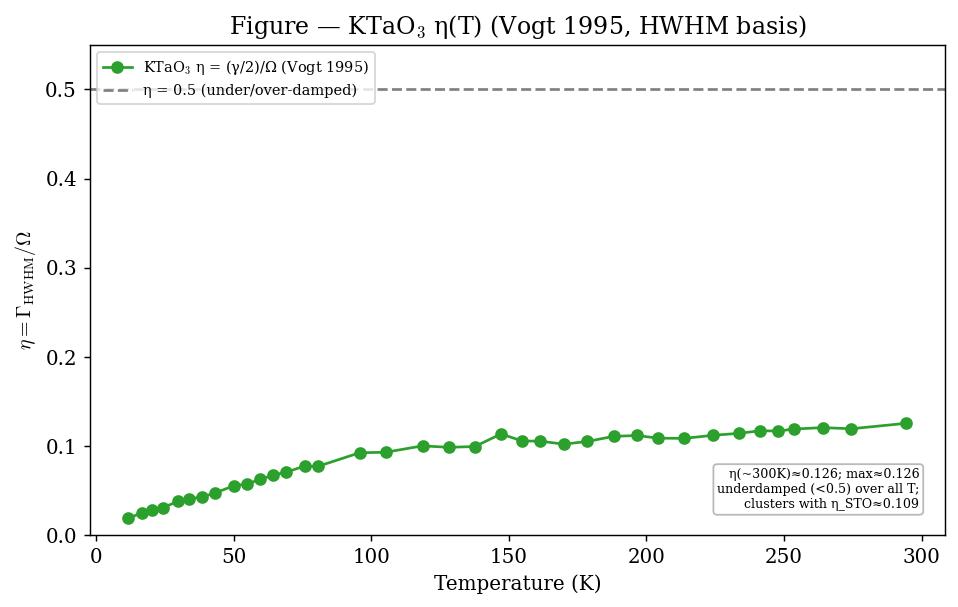

eta_KTO: ~300K = 0.126; max over T = 0.126 (HWHM basis, gamma/2)
(eta_fit() in eta.py will fit this; here it is the inline benchmark curve.)
  [OK ] KTaO3 eta underdamped (<0.5) over all T  (max eta = 0.126; eta(300K)=0.126)


In [3]:
vgg = lit.load_vogt1995_kto_gamma_T()
T_eta, eta = eta_curve(vog95, vgg, ocol="Omega_meV", ometh="exp_HyperRaman_Vogt1995")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(T_eta, eta, marker="o", color="tab:green", ls="-", label="KTaO$_3$ η = (γ/2)/Ω (Vogt 1995)")
ax.axhline(0.5, color="0.5", ls="--", label="η = 0.5 (under/over-damped)")
ax.set_xlabel("Temperature (K)"); ax.set_ylabel(r"$\eta = \Gamma_{\rm HWHM}/\Omega$")
ax.set_ylim(0, 0.55); ax.set_title("Figure — KTaO$_3$ η(T) (Vogt 1995, HWHM basis)")
ax.legend(fontsize=8, loc="upper left")
eta_300 = float(eta[-1]); eta_max = float(np.nanmax(eta))
ax.text(0.97, 0.05, f"η(~300K)≈{eta_300:.3f}; max≈{eta_max:.3f}\nunderdamped (<0.5) over all T;\nclusters with η_STO≈0.109",
        transform=ax.transAxes, fontsize=7, ha="right", va="bottom", bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_KTaO3_eta_T.{ext}", dpi=150, bbox_inches="tight")
plt.show()
print(f"eta_KTO: ~300K = {eta_300:.3f}; max over T = {eta_max:.3f} (HWHM basis, gamma/2)")
print("(eta_fit() in eta.py will fit this; here it is the inline benchmark curve.)")
flag("KTaO3 eta underdamped (<0.5) over all T", eta_max < 0.5, f"max eta = {eta_max:.3f}; eta(300K)={eta_300:.3f}")


## 3. Λ²_KTO stays a bracket (all sources q=0)


In [4]:
disp = lit.load_meier2022_dispersion_T()
soft = disp[disp["branch"] == "Soft_Optical"]
print("Lambda^2_KTO status:")
print(f" - Meier Fig. 2 soft branch: q-points = {sorted(soft['q_label'].unique())} -> Gamma-only, no small-q curvature.")
print(" - Vogt Fig. 5 & Ranalli Fig. 4(a): q=0 Omega(T) only (no dispersion).")
print(" - => NO KTaO3 source has near-Gamma small-q dispersion to fit Lambda^2 directly.")
print(" - DECISION (Amendment-2 §7/§12): Lambda^2_KTO = STO-proxy central, +/-50% BRACKET.")
print("   Fallback if a referee demands rigor: re-digitize Ranalli Fig. 3 near-Gamma TO")
print("   (a calculated full-BZ band; |q|<~0.15 A^-1 curvature) -- not done unless needed.")
print(" - KTaO3 is an interior-point anchor for Section 4; a bracketed Lambda^2 suffices.")
flag("Lambda^2_KTO correctly bracketed (no q=0-only source over-claimed as a fit)",
     set(soft["q_label"].unique()) == {"Gamma"}, "Meier soft branch Gamma-only")


Lambda^2_KTO status:
 - Meier Fig. 2 soft branch: q-points = ['Gamma'] -> Gamma-only, no small-q curvature.
 - Vogt Fig. 5 & Ranalli Fig. 4(a): q=0 Omega(T) only (no dispersion).
 - => NO KTaO3 source has near-Gamma small-q dispersion to fit Lambda^2 directly.
 - DECISION (Amendment-2 §7/§12): Lambda^2_KTO = STO-proxy central, +/-50% BRACKET.
   Fallback if a referee demands rigor: re-digitize Ranalli Fig. 3 near-Gamma TO
   (a calculated full-BZ band; |q|<~0.15 A^-1 curvature) -- not done unless needed.
 - KTaO3 is an interior-point anchor for Section 4; a bracketed Lambda^2 suffices.
  [OK ] Lambda^2_KTO correctly bracketed (no q=0-only source over-claimed as a fit)  (Meier soft branch Gamma-only)


## 4. LST INTERNAL consistency (Ranalli 1/ε vs Ranalli Ω², both MLFF+SSCHA) + Barrett $T_1$


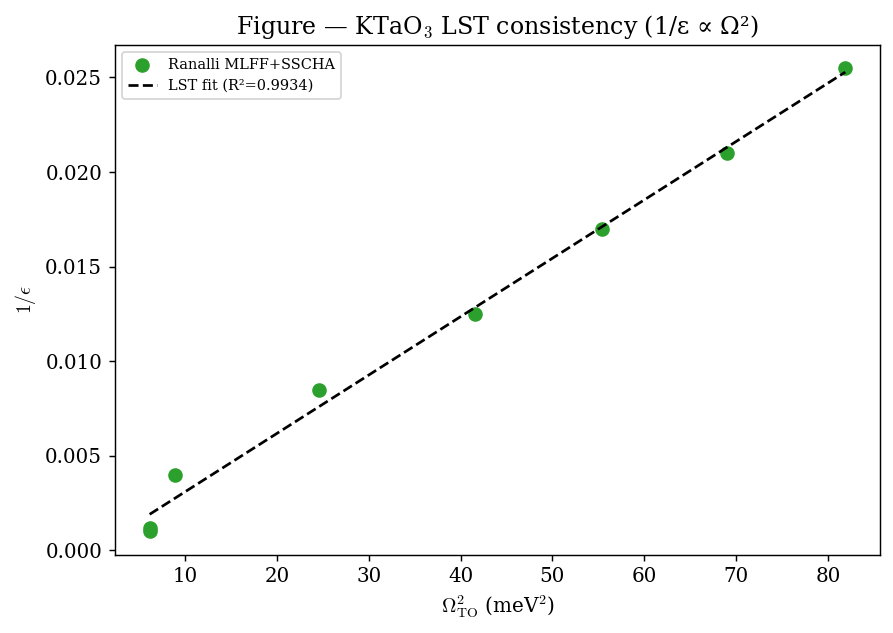

KTaO3 LST: Ranalli 1/eps(MLFF+SSCHA) vs Ranalli Omega^2(MLFF+SSCHA) -> R^2 = 0.9934 (8 matched T)
  This is INTERNAL consistency of the Ranalli calculation (1/eps and Omega both
  MLFF+SSCHA), parallel to STO's Verdi-vs-Verdi LST (0.9978) -- NOT a cross-source
  experiment-vs-calculation test. (A cross-source 1/eps-vs-Vogt-Omega^2 check would
  be the stronger validation but mixes sources; deferred.)
Barrett/QPE scale (Vogt model_params.md, metadata): T1 ~ 50-55 K (Barrett/RSL/sextic
fits) = canonical KTaO3 quantum-paraelectric saturation temperature; Curie-Weiss
breaks down below ~T1 (Barrett saturation in 1/eps). NOTE: model_params.md is
metadata only -- no Omega(T) reconstructed from it.
  [OK ] KTaO3 LST R^2 >= 0.9  (R^2=0.9934)


In [5]:
eps = lit.load_ranalli2023_inverse_dielectric_T()
em = eps[eps["method"] == "MLFF+SSCHA"].sort_values("T_K")
om = ran[ran["method"] == "MLFF+SSCHA"].sort_values("T_K")
mg = em.merge(om[["T_K", "Omega_meV"]], on="T_K", how="inner")
x = (mg["Omega_meV"].astype(float))**2; y = mg["inverse_epsilon"].astype(float)
A = np.vstack([x, np.ones_like(x)]).T
(slope, intc), *_ = np.linalg.lstsq(A, y, rcond=None)
yhat = slope*x + intc; R2 = 1 - ((y-yhat)**2).sum()/((y-y.mean())**2).sum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=50, color="tab:green", label="Ranalli MLFF+SSCHA")
xr = np.linspace(float(x.min()), float(x.max()), 50); ax.plot(xr, slope*xr+intc, "k--", label=f"LST fit (R²={R2:.4f})")
ax.set_xlabel(r"$\Omega_{\rm TO}^2$ (meV$^2$)"); ax.set_ylabel(r"$1/\epsilon$")
ax.set_title("Figure — KTaO$_3$ LST consistency (1/ε ∝ Ω²)"); ax.legend(fontsize=8)
fig.tight_layout()
for ext in ("png","pdf"): fig.savefig(FIG_DIR / f"fig_KTaO3_LST_consistency.{ext}", dpi=150, bbox_inches="tight")
plt.show()
print(f"KTaO3 LST: Ranalli 1/eps(MLFF+SSCHA) vs Ranalli Omega^2(MLFF+SSCHA) -> R^2 = {R2:.4f} ({len(mg)} matched T)")
print("  This is INTERNAL consistency of the Ranalli calculation (1/eps and Omega both")
print("  MLFF+SSCHA), parallel to STO's Verdi-vs-Verdi LST (0.9978) -- NOT a cross-source")
print("  experiment-vs-calculation test. (A cross-source 1/eps-vs-Vogt-Omega^2 check would")
print("  be the stronger validation but mixes sources; deferred.)")
print("Barrett/QPE scale (Vogt model_params.md, metadata): T1 ~ 50-55 K (Barrett/RSL/sextic")
print("fits) = canonical KTaO3 quantum-paraelectric saturation temperature; Curie-Weiss")
print("breaks down below ~T1 (Barrett saturation in 1/eps). NOTE: model_params.md is")
print("metadata only -- no Omega(T) reconstructed from it.")
flag("KTaO3 LST R^2 >= 0.9", R2 >= 0.9, f"R^2={R2:.4f}")


## 5. Gate


In [6]:
n_stop = sum(1 for _, ok, _ in FLAGS if not ok)
print("\nNB 07b flags:")
for item, ok, note in FLAGS:
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else ""))
print()
if n_stop:
    print(f"NB 07b GATE: STOP FOR SIGN-OFF ({n_stop} flag(s) tripped).")
else:
    print("NB 07b GATE: PASS. KTaO3 underdamped (eta~0.13<0.5), clusters w/ STO; Lambda^2 bracketed;")
    print("LST consistent; Vogt tie-breaks the Meier-Ranalli shift. STOP for sign-off (planned).")



NB 07b flags:
  [OK ] KTaO3 eta underdamped (<0.5) over all T  (max eta = 0.126; eta(300K)=0.126)
  [OK ] Lambda^2_KTO correctly bracketed (no q=0-only source over-claimed as a fit)  (Meier soft branch Gamma-only)
  [OK ] KTaO3 LST R^2 >= 0.9  (R^2=0.9934)

NB 07b GATE: PASS. KTaO3 underdamped (eta~0.13<0.5), clusters w/ STO; Lambda^2 bracketed;
LST consistent; Vogt tie-breaks the Meier-Ranalli shift. STOP for sign-off (planned).
